In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = {
    "YearsExperience": [1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 3.7, 4.0,
                        4.1, 4.5, 5.0, 5.2, 5.5, 6.0, 6.8, 7.1, 8.0, 9.0],
    "Salary": [39343, 46205, 37731, 43525, 39891, 56642, 60150, 54445, 57189, 63218,
               55794, 61111, 67938, 66029, 83088, 93940, 91738, 98273, 101302, 105582]
}
df = pd.DataFrame(data)
display(df)

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891
5,2.9,56642
6,3.0,60150
7,3.2,54445
8,3.7,57189
9,4.0,63218


In [3]:
X = df[["YearsExperience"]]
y = df["Salary"]
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (20, 1)
Target shape: (20,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16
Testing samples: 4


In [5]:
degrees = [1, 2, 3, 5, 10]
train_errors, test_errors, train_r2, test_r2 = [], [], [], []

In [6]:
for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    y_train_pred = model.predict(X_train_poly)
    y_test_pred = model.predict(X_test_poly)
    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)
    train_score = r2_score(y_train, y_train_pred)
    test_score = r2_score(y_test, y_test_pred)
    train_errors.append(train_mse)
    test_errors.append(test_mse)
    train_r2.append(train_score)
    test_r2.append(test_score)
    print("\nPolynomial Degree:", degree)
    print("Training MSE:", train_mse)
    print("Testing MSE:", test_mse)
    print("Training R2:", train_score)
    print("Testing R2:", test_score)


Polynomial Degree: 1
Training MSE: 20744204.8857099
Testing MSE: 93615404.34011638
Training R2: 0.9466284151164234
Testing R2: 0.8698559860480737

Polynomial Degree: 2
Training MSE: 20728000.5176637
Testing MSE: 92380320.45137054
Training R2: 0.9466701064133146
Testing R2: 0.8715729980717013

Polynomial Degree: 3
Training MSE: 20349492.72445246
Testing MSE: 71913099.96027242
Training R2: 0.9476439475861034
Testing R2: 0.9000265015087331

Polynomial Degree: 5
Training MSE: 16032429.106537417
Testing MSE: 173630149.4568411
Training R2: 0.9587510750272749
Testing R2: 0.7586195909458582

Polynomial Degree: 10
Training MSE: 4539377.324194768
Testing MSE: 71859379812.59544
Training R2: 0.9883208942684644
Testing R2: -98.89881681149365


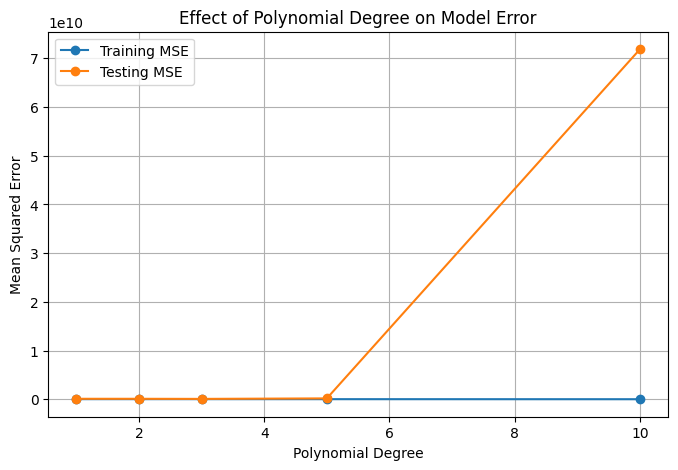

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(degrees, train_errors, marker="o", label="Training MSE")
plt.plot(degrees, test_errors, marker="o", label="Testing MSE")
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Effect of Polynomial Degree on Model Error")
plt.legend()
plt.grid(True)
plt.show()

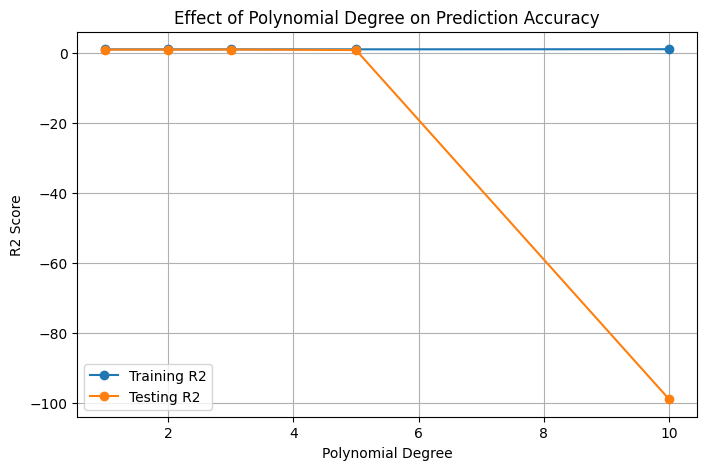

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(degrees, train_r2, marker="o", label="Training R2")
plt.plot(degrees, test_r2, marker="o", label="Testing R2")
plt.xlabel("Polynomial Degree")
plt.ylabel("R2 Score")
plt.title("Effect of Polynomial Degree on Prediction Accuracy")
plt.legend()
plt.grid(True)
plt.show()